In [1]:
print("Hello")

Hello


In [2]:
import os
from dotenv import load_dotenv

In [3]:
load_dotenv()

True

In [4]:
if not os.getenv("GROQ_API_KEY"):
    raise ValueError("Set GROQ_API_KEY in your environment/.env before running this notebook.")

### Mem0 Memory

In [ ]:
# mem0_config = {
#     "llm": {
#         "provider": "openai",
#         "config": {
#             "model": "gpt-4o-mini",
#             "api_key": os.environ["OPENAI_API_KEY"],
#             "temperature": 0,
#         },
#     },
#     "embedder": {
#         "provider": "huggingface",
#         "config": {
#             "model": "all-MiniLM-L6-v2",
#         },
#     },
#     "vector_store": {
#         "provider": "qdrant",
#         "config": {
#             "path": "./data/mem0-qdrant",
#             "embedding_model_dims": 384,
#         },
#     },
# }


In [5]:
import os
from mem0 import Memory

mem0_config = {
    "llm": {
        "provider": "groq",
        "config": {
            "model": "openai/gpt-oss-120b",
            "api_key": os.environ["GROQ_API_KEY"],
            "temperature": 0,
        },
    },
    "embedder": {
        "provider": "huggingface",
        "config": {
            "model": "all-MiniLM-L6-v2",
        },
    },
    "vector_store": {
        "provider": "qdrant",
        "config": {
            "path": "./data/mem0-qdrant",
            "embedding_model_dims": 384,
        },
    },
}

m = Memory.from_config(mem0_config)

/Users/amanladkat/Desktop/Customer Support Agent/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1022 17:21:11.770000 25411 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 12801.15it/s]
/Users/amanladkat/Desktop/Customer Support Agent/.venv/lib/python3.12/site-packages/mem0/embeddings/huggingface.py:29: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self.config.embedding_dims = self.config.embedding_dims or self.model.get_sentence_embedding_dimension()
[PostHog] Multiple active PostHog clients detected for the same project API key and host. Reuse one Posthog instance per app or process when possible to avoid competi

In [ ]:
from mem0 import Memory

m = Memory.from_config(mem0_config)

In [7]:
result = m.add(
    "Alex loves basketball and gaming.",
    user_id="alex",
    infer=False,
)
print(result)

{'results': [{'id': '19ced554-a6e3-4cfd-bfd3-d4006f74f66e', 'memory': 'Alex loves basketball and gaming.', 'event': 'ADD', 'actor_id': None, 'role': 'user'}]}


In [9]:
results = m.search(
    query="What are Alex's interests?",
    filters={"user_id": "alex"},
)

print(results)

{'results': [{'id': '19ced554-a6e3-4cfd-bfd3-d4006f74f66e', 'memory': 'Alex loves basketball and gaming.', 'hash': '89a4cb21b5ea7abee91395300e674451', 'metadata': None, 'score': 0.3357035861050901, 'created_at': '2026-10-22T11:51:42.716246+00:00', 'updated_at': '2026-10-22T11:51:42.716246+00:00', 'user_id': 'alex', 'role': 'user'}, {'id': '4eac5556-1073-43f3-9998-64520f588729', 'memory': "User's name is Alex and they love basketball and gaming.", 'hash': '9b758a2368e12e4fd82a7545b3cac870', 'metadata': None, 'score': 0.2595130519456582, 'created_at': '2026-10-19T17:57:36.371458+00:00', 'updated_at': '2026-10-19T17:57:36.371458+00:00', 'user_id': 'alex', 'attributed_to': 'user'}]}


/Users/amanladkat/Desktop/Customer Support Agent/.venv/lib/python3.12/site-packages/mem0/vector_stores/qdrant.py:177: UserWarning: Payload indexes have no effect in the local Qdrant. Please use server Qdrant if you need payload indexes.
  self.client.create_payload_index(


In [11]:
results = m.search(query="What do you know about me?", filters={"user_id": "alex"},)
print(results)

{'results': [{'id': '4eac5556-1073-43f3-9998-64520f588729', 'memory': "User's name is Alex and they love basketball and gaming.", 'hash': '9b758a2368e12e4fd82a7545b3cac870', 'metadata': None, 'score': 0.17434961692524073, 'created_at': '2026-10-19T17:57:36.371458+00:00', 'updated_at': '2026-10-19T17:57:36.371458+00:00', 'user_id': 'alex', 'attributed_to': 'user'}, {'id': '19ced554-a6e3-4cfd-bfd3-d4006f74f66e', 'memory': 'Alex loves basketball and gaming.', 'hash': '89a4cb21b5ea7abee91395300e674451', 'metadata': None, 'score': 0.1275866450076909, 'created_at': '2026-10-22T11:51:42.716246+00:00', 'updated_at': '2026-10-22T11:51:42.716246+00:00', 'user_id': 'alex', 'role': 'user'}]}


In [12]:
results = m.search(query="What do you know about me?", filters={"user_id": "yash"},)
print(results)

{'results': []}


In [14]:
messages = [
    {"role": "user", "content": "Hi, I'm Yash. I love chess and programming."},
    {"role": "assistant", "content": "Hey Yash! I'll remember your interests."}
]

result = m.add(
    messages,
    user_id="yash",
    infer=False
)

print(result)

{'results': [{'id': '35a0a979-7ca3-4f5d-8922-487c8e213f7b', 'memory': "Hi, I'm Yash. I love chess and programming.", 'event': 'ADD', 'actor_id': None, 'role': 'user'}, {'id': '2d27e007-8dd9-4826-8700-de0e2b059fbd', 'memory': "Hey Yash! I'll remember your interests.", 'event': 'ADD', 'actor_id': None, 'role': 'assistant'}]}


In [15]:
results = m.search(query="What do you know about me?", filters={"user_id": "yash"},)
print(results)

{'results': [{'id': '2d27e007-8dd9-4826-8700-de0e2b059fbd', 'memory': "Hey Yash! I'll remember your interests.", 'hash': 'e515c5a41ed8e9327fe7dff1fbc2fb2a', 'metadata': None, 'score': 0.26394253207302465, 'created_at': '2026-10-22T11:57:40.817258+00:00', 'updated_at': '2026-10-22T11:57:40.817258+00:00', 'user_id': 'yash', 'role': 'assistant'}, {'id': '35a0a979-7ca3-4f5d-8922-487c8e213f7b', 'memory': "Hi, I'm Yash. I love chess and programming.", 'hash': 'ad8640b8392836fad2b03d40b0468005', 'metadata': None, 'score': 0.2214805565740316, 'created_at': '2026-10-22T11:57:40.693795+00:00', 'updated_at': '2026-10-22T11:57:40.693795+00:00', 'user_id': 'yash', 'role': 'user'}]}


In [16]:
results = m.search(
    query="What are Yash's interests?",
    filters={"user_id": "yash"}
)

print(results)

{'results': [{'id': '2d27e007-8dd9-4826-8700-de0e2b059fbd', 'memory': "Hey Yash! I'll remember your interests.", 'hash': 'e515c5a41ed8e9327fe7dff1fbc2fb2a', 'metadata': None, 'score': 0.41061846203920516, 'created_at': '2026-10-22T11:57:40.817258+00:00', 'updated_at': '2026-10-22T11:57:40.817258+00:00', 'user_id': 'yash', 'role': 'assistant'}, {'id': '35a0a979-7ca3-4f5d-8922-487c8e213f7b', 'memory': "Hi, I'm Yash. I love chess and programming.", 'hash': 'ad8640b8392836fad2b03d40b0468005', 'metadata': None, 'score': 0.22534050459990626, 'created_at': '2026-10-22T11:57:40.693795+00:00', 'updated_at': '2026-10-22T11:57:40.693795+00:00', 'user_id': 'yash', 'role': 'user'}]}


### Langchain Agents

In [18]:
from langchain_groq import ChatGroq

In [20]:
from langchain_groq import ChatGroq

llm_groq = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    max_tokens=128,
)

response = llm_groq.invoke("Hi! I am Yash.")
print(response.content)

Hello Yash! 👋 How can I help you today?


In [27]:
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))



langchain: 0.3.30
langchain-core: 0.3.86


In [29]:
from langgraph.prebuilt import create_react_agent
from langchain.tools import tool

/Users/amanladkat/Desktop/Customer Support Agent/.venv/lib/python3.12/site-packages/langgraph/checkpoint/base/__init__.py:17: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer
<frozen abc>:106: LangGraphDeprecatedSinceV10: AgentStatePydantic has been moved to `langchain.agents`. Please update your import to `from langchain.agents import AgentStatePydantic`. Deprecated in LangGraph V1.0 to be removed in V2.0.


In [30]:
@tool
def dummy_tool(inputText:str)-> str:
    """Convert input text to uppercase. This is just for testing.
     Arguments:
        inputText {str} -- input text to be converted to uppercase
    """
    return f"Outputs : {inputText.upper()}"

In [31]:
my_tools = [dummy_tool]

In [32]:
my_agent = create_react_agent(model=llm_groq,tools=my_tools)

/var/folders/m4/fr_h9tdx38dgfjt_mhlh6tzh0000gn/T/ipykernel_25411/4064366755.py:1: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  my_agent = create_react_agent(model=llm_groq,tools=my_tools)


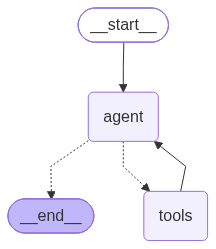

In [33]:
my_agent

In [34]:
res = my_agent.invoke({"messages":[("user","hi! i am yash")]})

In [35]:
res

{'messages': [HumanMessage(content='hi! i am yash', additional_kwargs={}, response_metadata={}, id='b87fa01d-0868-4136-aaa0-a2f58f951678'),
  AIMessage(content='Hello Yash! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'User says "hi! i am yash". We need to respond. Probably greet.'}, response_metadata={'token_usage': {'completion_tokens': 40, 'prompt_tokens': 149, 'total_tokens': 189, 'completion_time': 0.048920209, 'completion_tokens_details': {'reasoning_tokens': 18}, 'prompt_time': 0.008448501, 'prompt_tokens_details': None, 'queue_time': 0.33372143, 'total_time': 0.05736871}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_ef00694abe', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None}, id='run--01a16395-8ad0-7219-bac8-68eeeb0dea4b-0', usage_metadata={'input_tokens': 149, 'output_tokens': 40, 'total_tokens': 189})]}

In [36]:
res_with_tool = my_agent.invoke({"messages":[("user","hi! i am yash and i want to convert `Ai agent` to uppercase")]})

In [37]:
res_with_tool

{'messages': [HumanMessage(content='hi! i am yash and i want to convert `Ai agent` to uppercase', additional_kwargs={}, response_metadata={}, id='3f5abac0-9c96-4622-8549-6bb0694388e1'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'User wants to convert "Ai agent" to uppercase. There\'s a tool dummy_tool that converts input text to uppercase. We should call it.', 'tool_calls': [{'id': 'fc_88671dd9-a432-466f-a4cd-e2a84b5dd210', 'function': {'arguments': '{"inputText":"Ai agent"}', 'name': 'dummy_tool'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 55, 'prompt_tokens': 160, 'total_tokens': 215, 'completion_time': 0.06198777, 'completion_tokens_details': {'reasoning_tokens': 29}, 'prompt_time': 0.009923432, 'prompt_tokens_details': None, 'queue_time': 0.341465965, 'total_time': 0.071911202}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_d6de37e6be', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': 